# 05 · Web app guide: how the site works, and how to run it

**What this notebook covers.** The surveillance website in `web/` watches videos and camera streams,
finds animals, and keeps a log. This notebook explains how it is built, shows the person-versus-animal rule
on real test pictures, reads the log, and starts and stops the site so you can open it in a browser.

**What it does not do.** It does not change the model or the data, and it does not train anything.
The server only listens on `127.0.0.1` (this computer only).

**Prerequisites.** The model file `results/weights/best.pt` and the person model `yolov8n.pt` must exist.
Heavy steps run under a memory cap (`systemd-run`, 15 GB, no swap), one image at a time.

In [1]:
from pathlib import Path
import os

# Find the project root (the folder that holds PROJECT_PLAN.md) and work from there.
root = Path.cwd().resolve()
while not (root / "PROJECT_PLAN.md").exists():
    if root.parent == root:
        raise SystemExit("PROJECT_PLAN.md not found above this folder")
    root = root.parent
os.chdir(root)
print("project root:", root)

# Only for the offline runner in notebooks/run_notebook.py, whose IPython stand-in lacks these
# two attributes. Real Jupyter has them, so this block does nothing there.
import IPython
if not hasattr(IPython, "get_ipython"):
    IPython.get_ipython = lambda: None
    IPython.version_info = (8, 24, 0)
import warnings
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")

project root: /home/upicy/comp_vision


## Parameters

Change these here. Quick mode runs the rule demo on 10 test images; the full run uses all 80.

In [2]:
import sys

FULL_RUN = False                        # False = quick (10 test images). True = all 80.
DEMO_N = 80 if FULL_RUN else 10         # test images scanned by the rule demo
WEB_PORT = 5055                         # from web/config.json; the app listens on 127.0.0.1 only
MEM_CAP = "15G"                         # memory cap for every heavy subprocess
PY = sys.executable                     # this kernel's Python (the animal-det env)
WORK = Path("results/notebooks/05")     # pictures and logs written by this notebook

print("mode:", "FULL" if FULL_RUN else "quick")
print("python:", PY)

mode: quick
python: /home/upicy/.conda/envs/animal-det/bin/python


## 1. The architecture

Every frame, from an uploaded clip or a live camera, goes through the same steps:

```
frame ──► animal model (best.pt)  ──► animal boxes ─┐
  │        plain run + ByteTrack IDs                 ├─► person rule ─► SQLite log ─► Flask pages
  └────► person model (yolov8n)   ──► person boxes ─┘                    (Log, Stats, Animals,
                                                                           Gallery, Settings, Live)
```

| Part | File | Job |
|---|---|---|
| Detector | `web/detector.py` | Runs both models. Applies the person rule. Returns animal and person boxes. |
| Tracker | `web/detector.py` | ByteTrack gives each animal a track ID, so one animal is logged once, not every frame. |
| Event logger | `web/detector.py`, `web/events.py` | Decides what to log (de-duplicates, zone entry, missing animal). |
| Database | `web/db.py` | SQLite file `web/instance/detections.sqlite`: tables `detections`, `tracks`, `sources`, `zones`, `alerts`. |
| Web app | `web/app.py` | Flask routes and pages. Also a background thread that checks for missing animals every 5 seconds. |
| Settings | `web/config.json` plus the Settings page | Thresholds. The Settings page changes them while the app runs. |

Sections 2 to 6 walk through the parts in the order a frame meets them.

In [3]:
import json
import pandas as pd
from IPython.display import display

cfg = json.loads(Path("web/config.json").read_text())
keys = ["animal_weights", "person_weights", "imgsz", "animal_conf", "person_conf", "suppress_animal_iou",
        "suppress_containment", "person_override_conf", "dedupe_seconds", "presence_seconds",
        "missing_alert_minutes", "port", "host"]
display(pd.DataFrame({"setting": keys, "value": [str(cfg[k]) for k in keys]}))

,setting,value
0,animal_weights,results/weights/best.pt
1,person_weights,yolov8n.pt
2,imgsz,640
3,animal_conf,0.5
4,person_conf,0.25
5,suppress_animal_iou,0.3
6,suppress_containment,0.7
7,person_override_conf,0.8
8,dedupe_seconds,10
9,presence_seconds,30


## 2. The person-versus-animal rule

A person in a picture is often a *false animal* for a detector trained on animals: a face, a shirt or a pair of legs
can look like a dog or a cat, especially in dark frames. So the site asks the person model (COCO `person` class) first.
An animal box is **dropped** when it belongs to a person, that is when any of these holds:

1. its **centre** is inside a person box,
2. its overlap with a person box (**IoU**, intersection over union) is above `suppress_animal_iou` (0.3),
3. more than `suppress_containment` (0.7) of its area is inside a person box.

A box whose confidence is at least `person_override_conf` (0.8) is **kept** even next to a person, so a confident real cow
standing beside a person is still logged. The rule below is the same code as `web/detector.py`, copied here so you can read it.

In [4]:
def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    if inter <= 0:
        return 0.0
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    return inter / (area_a + area_b - inter)

def person_rule(box, person, conf):
    """Return why the animal box is dropped, or None to keep it."""
    if conf >= cfg["person_override_conf"]:
        return None                                    # confident animal: kept
    x1, y1, x2, y2 = box
    px1, py1, px2, py2 = person
    area = max((x2 - x1) * (y2 - y1), 1e-6)
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    if px1 <= cx <= px2 and py1 <= cy <= py2:
        return "centre inside person"
    if iou(box, person) > cfg["suppress_animal_iou"]:
        return "IoU above %.2f" % cfg["suppress_animal_iou"]
    iw = max(0.0, min(x2, px2) - max(x1, px1))
    ih = max(0.0, min(y2, py2) - max(y1, py1))
    if iw * ih / area > cfg["suppress_containment"]:
        return "most of box inside person"
    return None

Now the rule on five made-up boxes against one person box (drawn as a blue box). Each animal box gets a verdict.

,example,confidence,verdict
0,A cow beside the person,0.70,kept
1,B dog overlapping the edge,0.70,dropped: IoU above 0.30
2,C dog mostly on the person,0.60,dropped: centre inside person
3,"D goat, centre inside, low confidence",0.60,dropped: centre inside person
4,"E cow, centre inside, very confident",0.95,kept


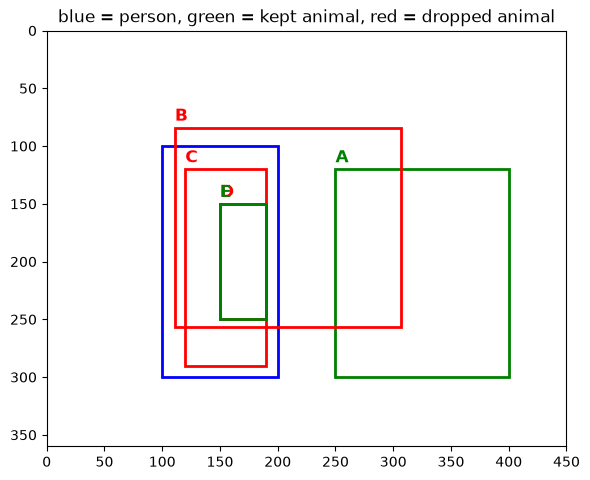

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

PERSON = (100, 100, 200, 300)
examples = {
    "A  cow beside the person": ((250, 120, 400, 300), 0.70),
    "B  dog overlapping the edge": ((111, 84, 307, 257), 0.70),
    "C  dog mostly on the person": ((120, 120, 190, 290), 0.60),
    "D  goat, centre inside, low confidence": ((150, 150, 190, 250), 0.60),
    "E  cow, centre inside, very confident": ((150, 150, 190, 250), 0.95),
}
rows = []
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(patches.Rectangle((PERSON[0], PERSON[1]), PERSON[2] - PERSON[0], PERSON[3] - PERSON[1],
                               fill=False, edgecolor="blue", linewidth=2))
for name, (box, conf) in examples.items():
    reason = person_rule(box, PERSON, conf)
    verdict = "kept" if reason is None else "dropped: " + reason
    rows.append({"example": name, "confidence": conf, "verdict": verdict})
    colour = "green" if reason is None else "red"
    ax.add_patch(patches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1],
                                   fill=False, edgecolor=colour, linewidth=2))
    ax.text(box[0], box[1] - 6, name[:1], color=colour, fontsize=12, weight="bold")
ax.set_xlim(0, 450); ax.set_ylim(360, 0); ax.set_aspect("equal")
ax.set_title("blue = person, green = kept animal, red = dropped animal")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows))

## 3. The rule on real test pictures

This step runs the real `Detector` from `web/detector.py` on the test images. It loads both models, so it runs in a
subprocess under the memory cap. For each picture it counts persons, animals before the rule, animals kept, and animals dropped.
Then it draws the picture with the chosen example: the picture with the most dropped animals.

The subprocess is started with `systemd-run --scope`, so the cap applies to it, not to this notebook.

In [6]:
import subprocess

JOB = r'''
import json, sys
from pathlib import Path
import cv2
sys.path.insert(0, "web")
from detector import Detector, load_config

n, out_dir = int(sys.argv[1]), Path(sys.argv[2])
out_dir.mkdir(parents=True, exist_ok=True)
cfg = load_config()
det = Detector(cfg)
images = sorted(Path("data/dataset/images/test").glob("*.jpg"))[:n]
rows, best = [], None
for img in images:
    frame = cv2.imread(str(img))
    animals, persons, suppressed = det.detect(frame)
    rows.append({"image": img.name, "persons": len(persons), "animals before rule": len(animals) + suppressed,
                 "animals kept": len(animals), "animals dropped": suppressed})
    score = (suppressed, len(persons))
    if best is None or score > best[0]:
        best = (score, img, frame, animals, persons)
_, img, frame, animals, persons = best
raw = det.animal_model.predict(frame, conf=cfg["animal_conf"], imgsz=cfg["imgsz"],
                               device=cfg["device"], verbose=False)[0]
kept = [a.box for a in animals]
pic = frame.copy()
for p in persons:
    cv2.rectangle(pic, (int(p.box[0]), int(p.box[1])), (int(p.box[2]), int(p.box[3])), (255, 0, 0), 3)
for b in raw.boxes.xyxy.tolist():
    is_kept = any(max(abs(x - y) for x, y in zip(b, k)) < 2.0 for k in kept)
    colour = (0, 200, 0) if is_kept else (0, 0, 255)
    cv2.rectangle(pic, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), colour, 3)
picture = out_dir / "rule_demo.jpg"
cv2.imwrite(str(picture), pic)
print(json.dumps({"rows": rows, "picture": str(picture), "chosen": img.name}))
'''

WORK.mkdir(parents=True, exist_ok=True)
cmd = ["systemd-run", "--user", "--scope", "-p", f"MemoryMax={MEM_CAP}", "-p", "MemorySwapMax=0",
       PY, "-c", JOB, str(DEMO_N), str(WORK)]
res = subprocess.run(cmd, capture_output=True, text=True, timeout=1800)
if res.returncode != 0:
    raise RuntimeError("rule demo failed:\n" + res.stderr[-2000:])
result = json.loads(res.stdout.strip().splitlines()[-1])

table = pd.DataFrame(result["rows"])
display(table)
print("totals:", table[["persons", "animals before rule", "animals kept", "animals dropped"]].sum().to_dict())

totals: {'persons': 3, 'animals before rule': 15, 'animals kept': 14, 'animals dropped': 1}


,image,persons,animals before rule,animals kept,animals dropped
0,openimages_yolo__00d84d869e53dcc4.jpg,0,2,2,0
1,openimages_yolo__05aa5a68579001d8.jpg,2,1,0,1
2,openimages_yolo__067b3591e94386b1.jpg,0,2,2,0
3,openimages_yolo__06f4e6d2fd724c62.jpg,0,1,1,0
4,openimages_yolo__07a255ff417d56d4.jpg,1,2,2,0
5,openimages_yolo__08bbb23bcff13936.jpg,0,1,1,0
6,openimages_yolo__093a4f837124f3ac.jpg,0,1,1,0
7,openimages_yolo__116629618d1b07b6.jpg,0,3,3,0
8,openimages_yolo__11b13f14591a1541.jpg,0,2,2,0
9,openimages_yolo__13348b909343dc2e.jpg,0,0,0,0


Picture chosen for the demo (blue = person, green = kept animal, red = animal dropped by the rule):

picture: openimages_yolo__05aa5a68579001d8.jpg


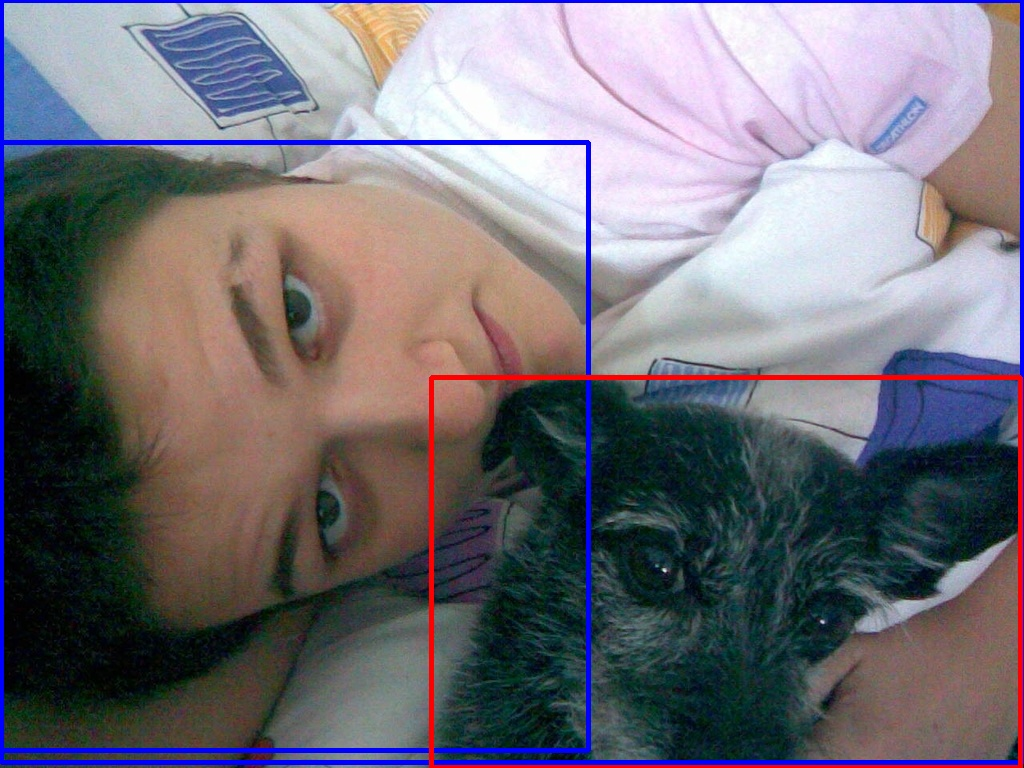

In [7]:
from IPython.display import Image, display
print("picture:", result["chosen"])
display(Image(filename=result["picture"], width=720))

## 4. Tracking: one animal, one track ID

The animal model runs twice on a frame. The plain run keeps every detection. The ByteTrack run (`model.track(persist=True)`)
gives an ID to each animal it follows from frame to frame. Each plain box takes the ID of the tracked box it overlaps most
(IoU of at least 0.5). A box with no match gets no ID; ByteTrack only reports a new track from its second frame,
so the first frame of each animal often has no ID (a known limit, see `web/README.md`).

The matching step is copied here so you can see it work on two made-up frames.

In [8]:
def track_for(box, tracked, min_iou=0.5):
    """The track ID of the tracked box that overlaps this box most, or None."""
    best, best_iou = None, min_iou
    for tbox, tid in tracked:
        v = iou(box, tbox)
        if v > best_iou:
            best, best_iou = tid, v
    return best

frame1 = {"dog A": (100, 100, 200, 220), "cow B": (400, 150, 520, 300)}
frame2 = {"dog A": (110, 104, 210, 224), "cow B": (405, 152, 525, 302)}   # both moved a little
tracked1 = [((100, 100, 200, 220), 1), ((400, 150, 520, 300), 2)]        # ByteTrack IDs, frame 1
rows = []
for name, b in frame2.items():
    rows.append({"frame 2 box": name, "matched track ID": track_for(b, tracked1),
                 "IoU with track": round(max(iou(b, t[0]) for t in tracked1), 2)})
display(pd.DataFrame(rows))

,frame 2 box,matched track ID,IoU with track
0,dog A,1,0.77
1,cow B,2,0.90


## 5. The log: what the SQLite database holds

Every logged animal (and every person row, which is kept separate) lands in the `detections` table, one row per box
per logged frame. `tracks` holds one row per track: first and last time seen, number of frames, and a snapshot.
`alerts` holds missing-animal and zone-entry alerts. The queries below open the database **read-only**, so they never
change the log. If the app is running it is fine to query at the same time.

In [9]:
import sqlite3

DB = "web/instance/detections.sqlite"
con = sqlite3.connect(f"file:{DB}?mode=ro", uri=True)

def query(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

display(query("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name"))

,name
0,alerts
1,detections
2,sources
3,sqlite_sequence
4,tracks
5,zones


### Sample log queries

These are the same kinds of questions the Stats and Log pages answer. Copy one and change the numbers to ask your own.

In [10]:
print("1) Counts per kind and class")
display(query("""
    SELECT kind, class_name, COUNT(*) AS boxes, ROUND(AVG(confidence), 2) AS avg_confidence
    FROM detections GROUP BY kind, class_name ORDER BY boxes DESC
"""))

print("2) The 10 newest log rows")
display(query("""
    SELECT ts, kind, class_name, ROUND(confidence, 2) AS confidence, source, clip_time, track_id
    FROM detections ORDER BY id DESC LIMIT 10
"""))

print("3) Tracks with the most frames (a long-lived track is a clear sighting)")
display(query("""
    SELECT source_id, track_id, class_name, frames, first_ts, last_ts
    FROM tracks ORDER BY frames DESC LIMIT 10
"""))

print("4) Safety check: animal rows whose class is 'person' (must be 0)")
display(query("SELECT COUNT(*) AS animal_rows_named_person FROM detections "
              "WHERE kind = 'animal' AND class_name = 'person'"))

print("5) Alerts by kind")
display(query("SELECT kind, COUNT(*) AS alerts FROM alerts GROUP BY kind"))

1) Counts per kind and class
2) The 10 newest log rows
3) Tracks with the most frames (a long-lived track is a clear sighting)
4) Safety check: animal rows whose class is 'person' (must be 0)
5) Alerts by kind


,kind,class_name,boxes,avg_confidence
0,animal,cow,132,0.79
1,person,person,9,0.64
2,animal,cat,6,0.64
3,animal,dog,5,0.53
4,animal,goat,2,0.70


,ts,kind,class_name,confidence,source,clip_time,track_id
0,2026-11-15T22:59:52+05:45,animal,cow,0.89,camera:http://127.0.0.1:8099/,None,4.0
1,2026-11-15T22:59:47+05:45,animal,cow,0.71,camera:http://127.0.0.1:8099/,None,3.0
2,2026-11-15T22:59:45+05:45,animal,cow,0.60,camera:http://127.0.0.1:8099/,None,2.0
3,2026-11-15T22:59:43+05:45,animal,cow,0.96,camera:http://127.0.0.1:8099/,None,1.0
4,2026-11-15T22:58:30+05:45,animal,cow,0.96,camera:http://127.0.0.1:8099/,None,18.0
5,2026-11-15T22:58:30+05:45,animal,cow,0.96,camera:http://127.0.0.1:8099/,None,NaN
6,2026-11-15T22:58:14+05:45,animal,cow,0.89,camera:http://127.0.0.1:8099/,None,17.0
7,2026-11-15T22:58:09+05:45,animal,cow,0.71,camera:http://127.0.0.1:8099/,None,16.0
8,2026-11-15T22:58:07+05:45,animal,cow,0.60,camera:http://127.0.0.1:8099/,None,15.0
9,2026-11-15T22:58:05+05:45,animal,cow,0.96,camera:http://127.0.0.1:8099/,None,14.0


,source_id,track_id,class_name,frames,first_ts,last_ts
0,camera-72b330f9,6,cow,25,2026-11-15T22:33:08+05:45,2026-11-15T22:33:12+05:45
1,camera-72b330f9,19,cow,25,2026-11-15T22:33:52+05:45,2026-11-15T22:33:56+05:45
2,camera-72b330f9,32,cow,25,2026-11-15T22:34:37+05:45,2026-11-15T22:34:41+05:45
3,camera-72b330f9,45,cow,25,2026-11-15T22:35:21+05:45,2026-11-15T22:35:25+05:45
4,camera-72b330f9,58,cow,25,2026-11-15T22:36:04+05:45,2026-11-15T22:36:08+05:45
5,camera-3ee0d5a8,6,cow,25,2026-11-15T22:41:16+05:45,2026-11-15T22:41:23+05:45
6,camera-b8f5ba1e,6,cow,25,2026-11-15T22:57:18+05:45,2026-11-15T22:57:24+05:45
7,camera-72b330f9,11,cow,24,2026-11-15T22:33:23+05:45,2026-11-15T22:33:27+05:45
8,camera-72b330f9,24,cow,24,2026-11-15T22:34:08+05:45,2026-11-15T22:34:12+05:45
9,camera-72b330f9,37,cow,24,2026-11-15T22:34:52+05:45,2026-11-15T22:34:55+05:45


,animal_rows_named_person
0,0


,kind,alerts
0,missing,58
1,zone,24


## 6. Start the website (in the background) and check it

The cell below starts `web/app.py` in its own memory-capped scope and waits until the site answers.
It does not start a second copy if one is already on the port. The next cell checks the main pages.
Open the site yourself at the address it prints; stop it with the stop cell below.

In [11]:
import time
import urllib.request

UNIT = "nb05-web"
BASE = f"http://127.0.0.1:{WEB_PORT}"

def server_up():
    try:
        with urllib.request.urlopen(BASE + "/api/summary", timeout=2) as r:
            return r.status == 200
    except Exception:
        return False

server_started = False
if server_up():
    print("a server is already on", BASE, "- not starting another one")
else:
    WORK.mkdir(parents=True, exist_ok=True)
    LOG = WORK / "web_server.log"
    logfile = open(LOG, "w")
    server = subprocess.Popen(["systemd-run", "--user", "--scope", f"--unit={UNIT}",
                               "-p", f"MemoryMax={MEM_CAP}", "-p", "MemorySwapMax=0",
                               PY, "web/app.py"], stdout=logfile, stderr=subprocess.STDOUT)
    server_started = True
    for _ in range(180):
        if server_up() or server.poll() is not None:
            break
        time.sleep(1)
    print("site up:", server_up(), "at", BASE + "/", "| log:", LOG)
    if not server_up():
        print(LOG.read_text()[-1500:])

site up: True at http://127.0.0.1:5055/ | log: results/notebooks/05/web_server.log


In [12]:
pages = ["/", "/live", "/log", "/animals", "/stats", "/gallery", "/events", "/settings", "/report", "/api/summary"]
status = []
for p in pages:
    try:
        with urllib.request.urlopen(BASE + p, timeout=10) as r:
            status.append({"page": p, "status": r.status, "bytes": len(r.read())})
    except Exception as exc:
        status.append({"page": p, "status": str(exc)[:60], "bytes": 0})
display(pd.DataFrame(status))

,page,status,bytes
0,/,200,4680
1,/live,200,4680
2,/log,200,32246
3,/animals,200,48569
4,/stats,200,23313
5,/gallery,200,26184
6,/events,200,13340
7,/settings,200,5302
8,/report,200,8247
9,/api/summary,200,394


## 7. Stop the website

Run this when you are done. It stops the scope started above. If the site was already running before this notebook,
it is left alone.

In [13]:
if server_started:
    subprocess.run(["systemctl", "--user", "stop", UNIT + ".scope"], capture_output=True, text=True)
    time.sleep(2)
print("site still answering:", server_up())

site still answering: False


## Limits to know

- The person rule drops an animal box, so a real animal standing right against a person can be missed unless it is confident.
- The first frame of an animal often has no track ID.
- Mascots and inflatable toys can look like cows to the model.
- Thresholds on the Settings page apply to the running app; `web/config.json` sets the starting values.

Full user guide: `web/README.md`. Test log: `web/QA.md`.